# 特徵工程與模型基準

時域+FFT 自製特徵 vs 官方 561 特徵；RF/SVM；subject-wise CV 混淆分析。

**一句話結論：特徵 > 模型。** 43→49 維（+6 姿態幾何）把準確率從 80% 拉到
89-90%、SITTING 召回 54%→80%；而換三種模型在 49 維上都買不到同樣的增益。
本 notebook 用真實視窗與已存報告（`data/processed/*.json`）重現這條故事線。


In [1]:

import sys; sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# dataviz 慣例（與 reports/figures 同一視覺系統）
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlesize": 10.5,
})

from src.isa.config import UCI_DIR, ACTIVITY_LABELS
from src.isa.data.loader import load_raw_signals, load_labels, load_subjects
from src.isa.features.time_domain import extract_time_features, FEATURE_NAMES as TIME_NAMES
from src.isa.features.freq_domain import extract_freq_features, FEATURE_NAMES as FREQ_NAMES
from src.isa.features.posture import extract_posture_features, FEATURE_NAMES as POST_NAMES
from src.isa.models.train import make_model
import json

X = load_raw_signals(UCI_DIR, "train")
y = load_labels(UCI_DIR, "train")
PROC = __import__("pathlib").Path("../data/processed")


## 1. 同一個特徵棧，看坐與走各長什麼樣

抽一個 SITTING 視窗與一個 WALKING 視窗，各算 49 維特徵
（時域 27＋頻域 16＋姿態幾何 6）逐項對照。


In [2]:
i_sit = int(np.flatnonzero(y == 4)[0])
i_walk = int(np.flatnonzero(y == 1)[0])
two = np.stack([X[i_sit], X[i_walk]])

feats = np.hstack([extract_time_features(two),
                   extract_freq_features(two),
                   extract_posture_features(two)])
names = [*TIME_NAMES, *FREQ_NAMES, *POST_NAMES]
assert len(names) == feats.shape[1] == 49

df = pd.DataFrame(feats.T, columns=["SITTING", "WALKING"], index=names)
df["|Δ|"] = (df["SITTING"] - df["WALKING"]).abs()
df.round(3)


,SITTING,WALKING,|Δ|
acc_x_mean,-0.027000,0.001000,0.028
acc_x_std,0.032000,0.219000,0.186
acc_x_mad,0.028000,0.123000,0.096
acc_x_range,0.107000,1.026000,0.918
acc_x_energy,0.002000,0.048000,0.046
acc_x_sma,0.032000,0.170000,0.138
acc_y_mean,0.108000,-0.011000,0.119
acc_y_std,0.141000,0.149000,0.008
acc_y_mad,0.086000,0.083000,0.003
acc_y_range,0.422000,0.666000,0.243


兩個視窗差最大的維度幾乎全是**頻域與能量類**（走的節奏與幅度），
而 SITTING 的 `gravity_*`／`angle_*` 維度編碼了「軀幹前傾的角度」——
這正是 43 維版缺的東西。

## 2. 主戰績：三種特徵軌 × subject-wise CV

所有數字來自 `data/processed/report_cv_*.json`（GroupKFold 5 折、受試者
零重疊）。自製 43 維 → 加姿態 49 維 → 官方 561 維 → 兩者併集 604 維。


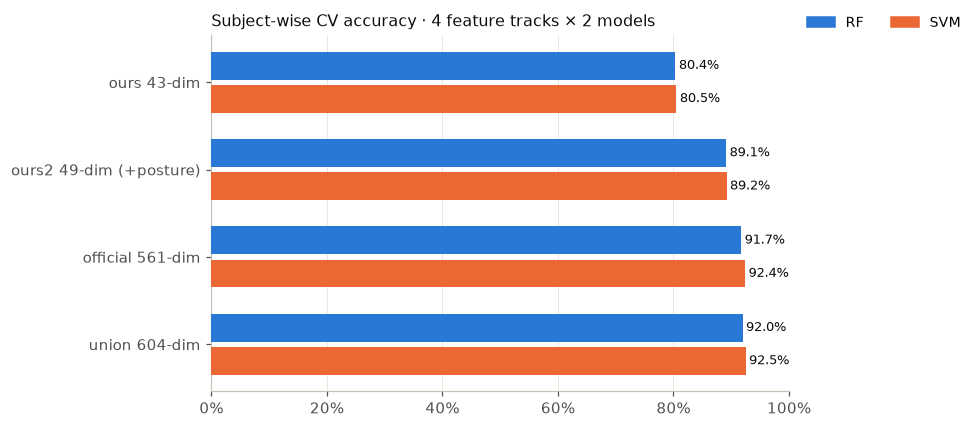

In [3]:
TRACKS = {
    "ours 43-dim": "../data/processed/cv_report_ours.json",
    "ours2 49-dim (+posture)": "../data/processed/report_cv_ours2.json",
    "official 561-dim": "../data/processed/report_cv_uci.json",
    "union 604-dim": "../data/processed/report_cv_both.json",
}
rows = []
for track, p in TRACKS.items():
    rep = json.load(open(p, encoding="utf-8"))
    for model in ("rf", "svm"):
        rows.append({"track": track, "model": model.upper(),
                     "acc": rep[model]["mean_accuracy"],
                     "std": rep[model]["std_accuracy"]})
d = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
ytick = list(reversed(d["track"].unique()))
for i, track in enumerate(ytick):
    sub = d[d["track"] == track]
    for j, (model, color) in enumerate([("RF", BLUE), ("SVM", ORANGE)]):
        r = sub[sub["model"] == model].iloc[0]
        y = i + (0.19 if model == "RF" else -0.19)
        ax.barh(y, r["acc"], height=0.32, color=color, zorder=3)
        ax.text(r["acc"] + 0.006, y, f"{r['acc']:.1%}", va="center",
                fontsize=8.5, color=INK)
ax.set_yticks(range(len(ytick)), ytick)
ax.set_xlim(0, 1.0)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", lw=0.5, color=GRID); ax.set_axisbelow(True)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE)]
ax.legend(handles, ["RF", "SVM"], frameon=False, fontsize=9, ncol=2,
          loc="lower left", bbox_to_anchor=(1.01, 0.98))
ax.set_title("Subject-wise CV accuracy · 4 feature tracks × 2 models",
             loc="left", color=INK)
fig.tight_layout()
plt.show()


## 3. 官方 holdout 與 N2 階梯（為什麼停在 49 維）

官方 split（21 訓練→9 測試，與原始論文同條件）下 561 維 SVM 95.5%——
重現文獻 ~96%，證明管線可信，差距全是特徵的差距。N2 階梯逐一移植官方集
的家族（ECDF/頻帶能量/jerk），**單一家族買不到剩餘 5pp**——49 維是精簡集
最適解。


In [4]:
ladder = json.load(open("../data/processed/feature_ladder_official.json",
                        encoding="utf-8"))
rows = []
for rung, models in ladder.items():
    row = {"setting": rung, "dims": models.get("dims")}
    for kind, rep in models.items():
        if isinstance(rep, dict) and "accuracy" in rep:
            row[kind] = round(rep["accuracy"], 4)
    rows.append(row)
pd.DataFrame(rows).set_index("setting")


,dims,svm,rf,xgb
setting,,,,
ours2 (baseline),49,0.9036,0.8823,0.8829
ours2+ecdf,79,0.8982,0.8660,0.8755
ours2+bands,58,0.9023,0.8806,0.8823
ours2+ecdf+bands,88,0.8979,0.8636,0.8850
ours2+jerk,92,0.9077,0.8850,0.8877
ours2+jerk+bands,101,0.9077,0.8850,0.8850
uci-561 (anchor),561,0.9549,0.9287,0.9416


## 4. 混淆結構：SITTING↔STANDING 的修復史

49 維版 CV 的混淆矩陣——非對角殘留集中在 SITTING↔STANDING（坐/站加速度
幾乎無差，姿態幾何把 SITTING 召回 54%→80%，官方 561 維進一步到 89-90%）。


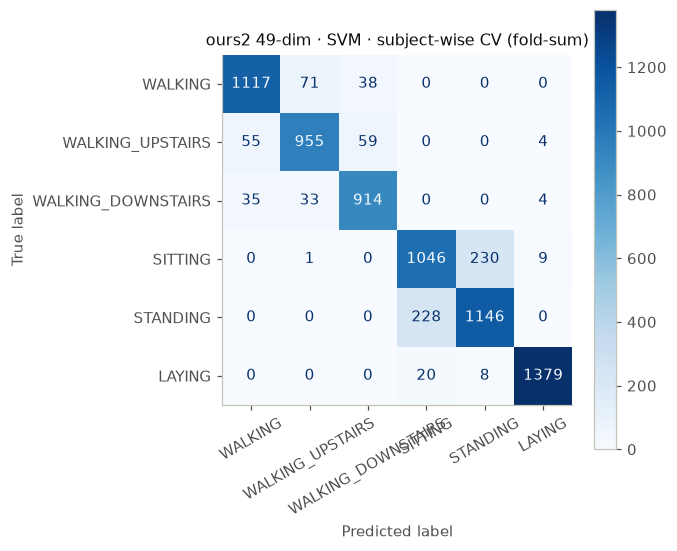

per-class recall: {'WALKING': np.float64(0.911), 'WALKING_UPSTAIRS': np.float64(0.89), 'WALKING_DOWNSTAIRS': np.float64(0.927), 'SITTING': np.float64(0.813), 'STANDING': np.float64(0.834), 'LAYING': np.float64(0.98)}


In [5]:
from sklearn.metrics import ConfusionMatrixDisplay

rep = json.load(open("../data/processed/report_cv_ours2.json", encoding="utf-8"))["svm"]
cm = np.array(rep["confusion_matrix"])
labels = [ACTIVITY_LABELS[c] for c in rep["labels"]]
fig, ax = plt.subplots(figsize=(6.2, 5.4))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(
    ax=ax, cmap="Blues", colorbar=True, values_format="d")
ax.set_title("ours2 49-dim · SVM · subject-wise CV (fold-sum)", color=INK,
             fontsize=10.5)
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

recall = dict(zip(labels, (cm.diagonal() / cm.sum(axis=1)).round(3), strict=True))
print("per-class recall:", recall)


## 小結

| 問題 | 答案 | 證據 |
|---|---|---|
| 43 維為何只有 80%？ | 缺姿態幾何 | +6 維 → 89-90%，SITTING 召回 +25pp |
| 換模型有救嗎？ | 沒有 | RF/SVM/XGB 在 49 維全部 ~88-89% |
| 剩餘 5pp 差距是什麼？ | 官方工程廣度 | N2 階梯：單一家族 +0.4pp 以內 |
| 部署該用哪一組？ | 49 維 ours2 | 8.7% 的維度換官方 94.7% 的表現 |
